# Phase 3 — Transfer Learning & Ablation Study (MobileNetV2 & ResNet50)

Eksperimen terkontrol di atas **splits.csv** yang sama persis dengan Phase 2 (`center_crop=True`, `224 × 224`, `Test Set` tetap **LOCKED** hingga Phase 4):

| Run ID | Backbone | Strategi | Preprocessing | Optimizer & LR |
| :--- | :--- | :--- | :--- | :--- |
| **Exp-2A** | MobileNetV2 | Stage 1: Frozen Feature Extractor | `[-1, 1]` in-model | `Adam(3e-4)` |
| **Exp-2B** | MobileNetV2 | Stage 2: Selective Fine-Tuning (top 30%, BN frozen) | `[-1, 1]` in-model | `AdamW(1e-5, wd=1e-4)` |
| **Exp-3A** | ResNet50 | Stage 1: Frozen Feature Extractor | BGR mean sub in-model | `Adam(3e-4)` |
| **Exp-3B** | ResNet50 | Stage 2: Selective Fine-Tuning (top 30%, BN frozen) | BGR mean sub in-model | `AdamW(1e-5, wd=1e-4)` |

**Target Baseline Phase 2 (`Exp-1B` Proper Scratch CNN):** `val_accuracy = 86.17%`, `val_recall = 83.10%`, `val_roc_auc = 0.9306`.

In [7]:
# Colab Auto-Bootstrap (Public GitHub + Fast GitHub Release Zip Cache)
import os
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/Indraku19/real-art-vs-ai-generated-art.git'
RELEASE_ZIP_URL = (
    'https://github.com/Indraku19/real-art-vs-ai-generated-art/releases/'
    'download/v1.0-dataset/processed_images_224.zip'
)
COLAB_DIR = Path('/content/real-art-vs-ai-generated-art')

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    if not COLAB_DIR.exists():
        subprocess.check_call(['git', 'clone', REPO_URL, str(COLAB_DIR)])
    else:
        subprocess.check_call(['git', '-C', str(COLAB_DIR), 'pull', '--ff-only'])
    os.chdir(COLAB_DIR)

    img_dir = Path('data/processed/images')
    img_dir.mkdir(parents=True, exist_ok=True)
    if not any(img_dir.iterdir()):
        zip_tmp = Path('/tmp/processed_images_224.zip')
        try:
            print('Downloading pre-cleaned 224x224 dataset cache from GitHub Release...')
            subprocess.check_call(['curl', '-fSL', RELEASE_ZIP_URL, '-o', str(zip_tmp)])
            with zipfile.ZipFile(zip_tmp, 'r') as zf:
                zf.extractall(img_dir)
            zip_tmp.unlink(missing_ok=True)
            print('Extracted images:', len(list(img_dir.glob('*.png'))))
        except Exception as exc:
            print('Release cache download failed, falling back to Hugging Face:', exc)
            subprocess.check_call([
                sys.executable, '-m', 'pip', 'install', '-q',
                'datasets', 'imagehash', 'huggingface_hub',
            ])
            env = {**os.environ, 'PYTHONPATH': str(COLAB_DIR)}
            subprocess.check_call([sys.executable, '-m', 'src.phase1_forensics'], env=env)
            subprocess.check_call([
                'git', 'checkout', '--',
                'data/processed/splits.csv',
                'data/processed/dataset_metadata.csv',
                'data/processed/forensics_summary.json',
                'reports/figures/phase1_data_forensics.png',
            ])

    if str(COLAB_DIR) not in sys.path:
        sys.path.insert(0, str(COLAB_DIR))
    print('Environment: Google Colab (Fast Zip) | Project Root:', Path.cwd())
else:
    if Path.cwd().name == 'notebooks':
        os.chdir(Path.cwd().parent)
    if str(Path.cwd()) not in sys.path:
        sys.path.insert(0, str(Path.cwd()))
    print('Environment: Local | Project Root:', Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment: Google Colab (Fast Zip) | Project Root: /content/real-art-vs-ai-generated-art


In [8]:
import json
import shutil
import time
from datetime import datetime
from typing import Literal

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_score, recall_score, roc_auc_score

from src.config import (
    EXPERIMENT_LOG_PATH,
    EXPERIMENTS_DIR,
    FIGURES_DIR,
    IMG_SIZE,
    MODELS_DIR,
    SEED,
    set_global_seed,
)
from src.data_pipeline import build_tf_dataset, get_preprocessing_layer, load_splits

set_global_seed(SEED)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs detected:', gpus if gpus else 'None (CPU mode)')

splits_df = load_splits()
train_ds = build_tf_dataset(splits_df, 'train', augment=True, center_crop=True, cache=True)
val_ds = build_tf_dataset(splits_df, 'val', augment=False, center_crop=True, cache=True)
print('Train batches:', len(train_ds), '| Val batches:', len(val_ds))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train batches: 71 | Val batches: 9


In [9]:
class EpochTimerCallback(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self._t0)


def build_transfer_model(backbone: Literal['mobilenetv2', 'resnet50']) -> tuple[keras.Model, keras.Model]:
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='raw_rgb_input')
    x = get_preprocessing_layer(backbone)(inputs)

    if backbone == 'mobilenetv2':
        base_model = keras.applications.MobileNetV2(
            include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3)
        )
    elif backbone == 'resnet50':
        base_model = keras.applications.ResNet50(
            include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3)
        )
    else:
        raise ValueError(f'Unknown backbone: {backbone}')

    base_model.trainable = False
    x = base_model(x)
    x = keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = keras.layers.Dropout(0.3, name='dropout_03')(x)
    x = keras.layers.Dense(128, activation='relu', name='dense_128')(x)
    x = keras.layers.Dropout(0.2, name='dropout_02')(x)
    outputs = keras.layers.Dense(1, activation='sigmoid', name='prob_ai')(x)
    model = keras.Model(inputs, outputs, name=f'tl_{backbone}')
    return model, base_model


def unfreeze_top_layers_keep_bn_frozen(base_model: keras.Model, unfreeze_ratio: float = 0.30) -> dict:
    base_model.trainable = True
    total_layers = len(base_model.layers)
    freeze_until = int(total_layers * (1.0 - unfreeze_ratio))

    bn_frozen = 0
    unfrozen_non_bn = 0
    for idx, layer in enumerate(base_model.layers):
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
            bn_frozen += 1
        elif idx < freeze_until:
            layer.trainable = False
        else:
            layer.trainable = True
            unfrozen_non_bn += 1

    info = {
        'total_backbone_layers': total_layers,
        'freeze_until_idx': freeze_until,
        'bn_layers_kept_frozen': bn_frozen,
        'unfrozen_non_bn_layers': unfrozen_non_bn,
    }
    print('Fine-tuning layer setup:', info)
    return info


def count_model_params(model: keras.Model) -> tuple[int, int, int]:
    trainable = int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))
    non_trainable = int(sum(int(np.prod(w.shape)) for w in model.non_trainable_weights))
    return trainable + non_trainable, trainable, non_trainable


def train_stage(
    model: keras.Model,
    ckpt_path: Path,
    optimizer: keras.optimizers.Optimizer,
    max_epochs: int = 20,
    patience: int = 5,
):
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
        ],
    )
    timer_cb = EpochTimerCallback()
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=patience, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(ckpt_path), monitor='val_loss', save_best_only=True, verbose=1
        ),
        timer_cb,
    ]
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=max_epochs,
        callbacks=callbacks,
        verbose=2,
    )
    return history, timer_cb.epoch_times


def evaluate_on_val(model: keras.Model) -> dict:
    y_true, y_prob = [], []
    for xb, yb in val_ds:
        preds = model.predict(xb, verbose=0).ravel()
        y_true.extend(yb.numpy().astype(int).tolist())
        y_prob.extend(preds.tolist())
    y_true = np.array(y_true)
    y_prob = np.clip(np.array(y_prob), 1e-7, 1.0 - 1e-7)
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        'val_loss': round(float(log_loss(y_true, y_prob)), 4),
        'val_accuracy': round(float(accuracy_score(y_true, y_pred)), 4),
        'val_precision': round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        'val_recall': round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        'val_f1': round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        'val_roc_auc': round(float(roc_auc_score(y_true, y_prob)), 4),
    }

In [10]:
# Exp-2A: MobileNetV2 — Stage 1 Frozen Feature Extractor
set_global_seed(SEED)
mnet_model, mnet_base = build_transfer_model('mobilenetv2')
p_total_2a, p_train_2a, p_nontrain_2a = count_model_params(mnet_model)
print(f'Exp-2A Params | total={p_total_2a:,} | trainable={p_train_2a:,} | frozen={p_nontrain_2a:,}')

exp2a_ckpt = MODELS_DIR / 'exp2a_mobilenetv2_frozen.keras'
exp2a_hist, exp2a_times = train_stage(
    mnet_model,
    exp2a_ckpt,
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    max_epochs=20,
    patience=5,
)
mnet_model.load_weights(str(exp2a_ckpt))
exp2a_val = evaluate_on_val(mnet_model)
print('Exp-2A Validation Metrics:', exp2a_val)

Exp-2A Params | total=2,422,081 | trainable=164,097 | frozen=2,257,984
Epoch 1/20

Epoch 1: val_loss improved from None to 0.22183, saving model to /content/real-art-vs-ai-generated-art/models/exp2a_mobilenetv2_frozen.keras

Epoch 1: finished saving model to /content/real-art-vs-ai-generated-art/models/exp2a_mobilenetv2_frozen.keras
71/71 - 165s - 2s/step - accuracy: 0.7926 - loss: 0.4413 - precision: 0.7996 - recall: 0.7827 - roc_auc: 0.8755 - val_accuracy: 0.9149 - val_loss: 0.2218 - val_precision: 0.9041 - val_recall: 0.9296 - val_roc_auc: 0.9776 - learning_rate: 3.0000e-04
Epoch 2/20

Epoch 2: val_loss improved from 0.22183 to 0.17606, saving model to /content/real-art-vs-ai-generated-art/models/exp2a_mobilenetv2_frozen.keras

Epoch 2: finished saving model to /content/real-art-vs-ai-generated-art/models/exp2a_mobilenetv2_frozen.keras
71/71 - 21s - 295ms/step - accuracy: 0.8941 - loss: 0.2617 - precision: 0.9041 - recall: 0.8825 - roc_auc: 0.9587 - val_accuracy: 0.9291 - val_loss: 

In [11]:
# Exp-2B: MobileNetV2 — Stage 2 Selective Fine-Tuning (top 30% non-BN layers)
set_global_seed(SEED)
mnet_ft_info = unfreeze_top_layers_keep_bn_frozen(mnet_base, unfreeze_ratio=0.30)
p_total_2b, p_train_2b, p_nontrain_2b = count_model_params(mnet_model)
print(f'Exp-2B Params | total={p_total_2b:,} | trainable={p_train_2b:,} | frozen={p_nontrain_2b:,}')

exp2b_ckpt = MODELS_DIR / 'exp2b_mobilenetv2_finetuned.keras'
exp2b_hist, exp2b_times = train_stage(
    mnet_model,
    exp2b_ckpt,
    optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
    max_epochs=20,
    patience=5,
)
mnet_model.load_weights(str(exp2b_ckpt))
exp2b_val = evaluate_on_val(mnet_model)
print('Exp-2B Validation Metrics:', exp2b_val)

Fine-tuning layer setup: {'total_backbone_layers': 154, 'freeze_until_idx': 107, 'bn_layers_kept_frozen': 52, 'unfrozen_non_bn_layers': 31}
Exp-2B Params | total=2,422,081 | trainable=1,943,233 | frozen=478,848
Epoch 1/20

Epoch 1: val_loss improved from None to 0.12725, saving model to /content/real-art-vs-ai-generated-art/models/exp2b_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /content/real-art-vs-ai-generated-art/models/exp2b_mobilenetv2_finetuned.keras
71/71 - 57s - 799ms/step - accuracy: 0.9508 - loss: 0.1252 - precision: 0.9522 - recall: 0.9496 - roc_auc: 0.9906 - val_accuracy: 0.9326 - val_loss: 0.1273 - val_precision: 0.9184 - val_recall: 0.9507 - val_roc_auc: 0.9922 - learning_rate: 1.0000e-05
Epoch 2/20

Epoch 2: val_loss did not improve from 0.12725
71/71 - 20s - 286ms/step - accuracy: 0.9566 - loss: 0.1058 - precision: 0.9624 - recall: 0.9505 - roc_auc: 0.9935 - val_accuracy: 0.9326 - val_loss: 0.1508 - val_precision: 0.8917 - val_recall: 0.9859 - val_ro

In [12]:
# Exp-3A: ResNet50 — Stage 1 Frozen Feature Extractor
set_global_seed(SEED)
resnet_model, resnet_base = build_transfer_model('resnet50')
p_total_3a, p_train_3a, p_nontrain_3a = count_model_params(resnet_model)
print(f'Exp-3A Params | total={p_total_3a:,} | trainable={p_train_3a:,} | frozen={p_nontrain_3a:,}')

exp3a_ckpt = MODELS_DIR / 'exp3a_resnet50_frozen.keras'
exp3a_hist, exp3a_times = train_stage(
    resnet_model,
    exp3a_ckpt,
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    max_epochs=20,
    patience=5,
)
resnet_model.load_weights(str(exp3a_ckpt))
exp3a_val = evaluate_on_val(resnet_model)
print('Exp-3A Validation Metrics:', exp3a_val)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Exp-3A Params | total=23,850,113 | trainable=262,401 | frozen=23,587,712
Epoch 1/20

Epoch 1: val_loss improved from None to 0.15130, saving model to /content/real-art-vs-ai-generated-art/models/exp3a_resnet50_frozen.keras

Epoch 1: finished saving model to /content/real-art-vs-ai-generated-art/models/exp3a_resnet50_frozen.keras
71/71 - 85s - 1s/step - accuracy: 0.8480 - loss: 0.3333 - precision: 0.8476 - recall: 0.8498 - roc_auc: 0.9312 - val_accuracy: 0.9397 - val_loss: 0.1513 - val_precision: 0.8981 - val_recall: 0.9930 - val_roc_auc: 0.9954 - learning_rate: 3.0000e-04
Epoch 2/20

Epoch 2: val_loss did not improve from 0.15130
71/71 - 21s - 295ms/step - accuracy: 0.9304 - loss: 0.1818 - precision: 0.9364 - recall: 0.9240 - roc_auc: 0.9795 - val_accuracy: 0.9113 - val_loss: 0.1692 - val_precision: 0.8545 - val_recall: 0.9930 - val_roc_auc: 0.9958 - learning_rate: 3.0000e-04
Epoch 3/20

Epoch 3: val_loss improved from 0.15130 to 0.085

In [13]:
# Exp-3B: ResNet50 — Stage 2 Selective Fine-Tuning (top 30% non-BN layers)
set_global_seed(SEED)
resnet_ft_info = unfreeze_top_layers_keep_bn_frozen(resnet_base, unfreeze_ratio=0.30)
p_total_3b, p_train_3b, p_nontrain_3b = count_model_params(resnet_model)
print(f'Exp-3B Params | total={p_total_3b:,} | trainable={p_train_3b:,} | frozen={p_nontrain_3b:,}')

exp3b_ckpt = MODELS_DIR / 'exp3b_resnet50_finetuned.keras'
exp3b_hist, exp3b_times = train_stage(
    resnet_model,
    exp3b_ckpt,
    optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
    max_epochs=20,
    patience=5,
)
resnet_model.load_weights(str(exp3b_ckpt))
exp3b_val = evaluate_on_val(resnet_model)
print('Exp-3B Validation Metrics:', exp3b_val)

Fine-tuning layer setup: {'total_backbone_layers': 175, 'freeze_until_idx': 122, 'bn_layers_kept_frozen': 53, 'unfrozen_non_bn_layers': 37}
Exp-3B Params | total=23,850,113 | trainable=17,447,169 | frozen=6,402,944
Epoch 1/20

Epoch 1: val_loss improved from None to 0.06954, saving model to /content/real-art-vs-ai-generated-art/models/exp3b_resnet50_finetuned.keras

Epoch 1: finished saving model to /content/real-art-vs-ai-generated-art/models/exp3b_resnet50_finetuned.keras
71/71 - 72s - 1s/step - accuracy: 0.9734 - loss: 0.0711 - precision: 0.9760 - recall: 0.9708 - roc_auc: 0.9970 - val_accuracy: 0.9681 - val_loss: 0.0695 - val_precision: 0.9524 - val_recall: 0.9859 - val_roc_auc: 0.9984 - learning_rate: 1.0000e-05
Epoch 2/20

Epoch 2: val_loss improved from 0.06954 to 0.05186, saving model to /content/real-art-vs-ai-generated-art/models/exp3b_resnet50_finetuned.keras

Epoch 2: finished saving model to /content/real-art-vs-ai-generated-art/models/exp3b_resnet50_finetuned.keras
71/71 

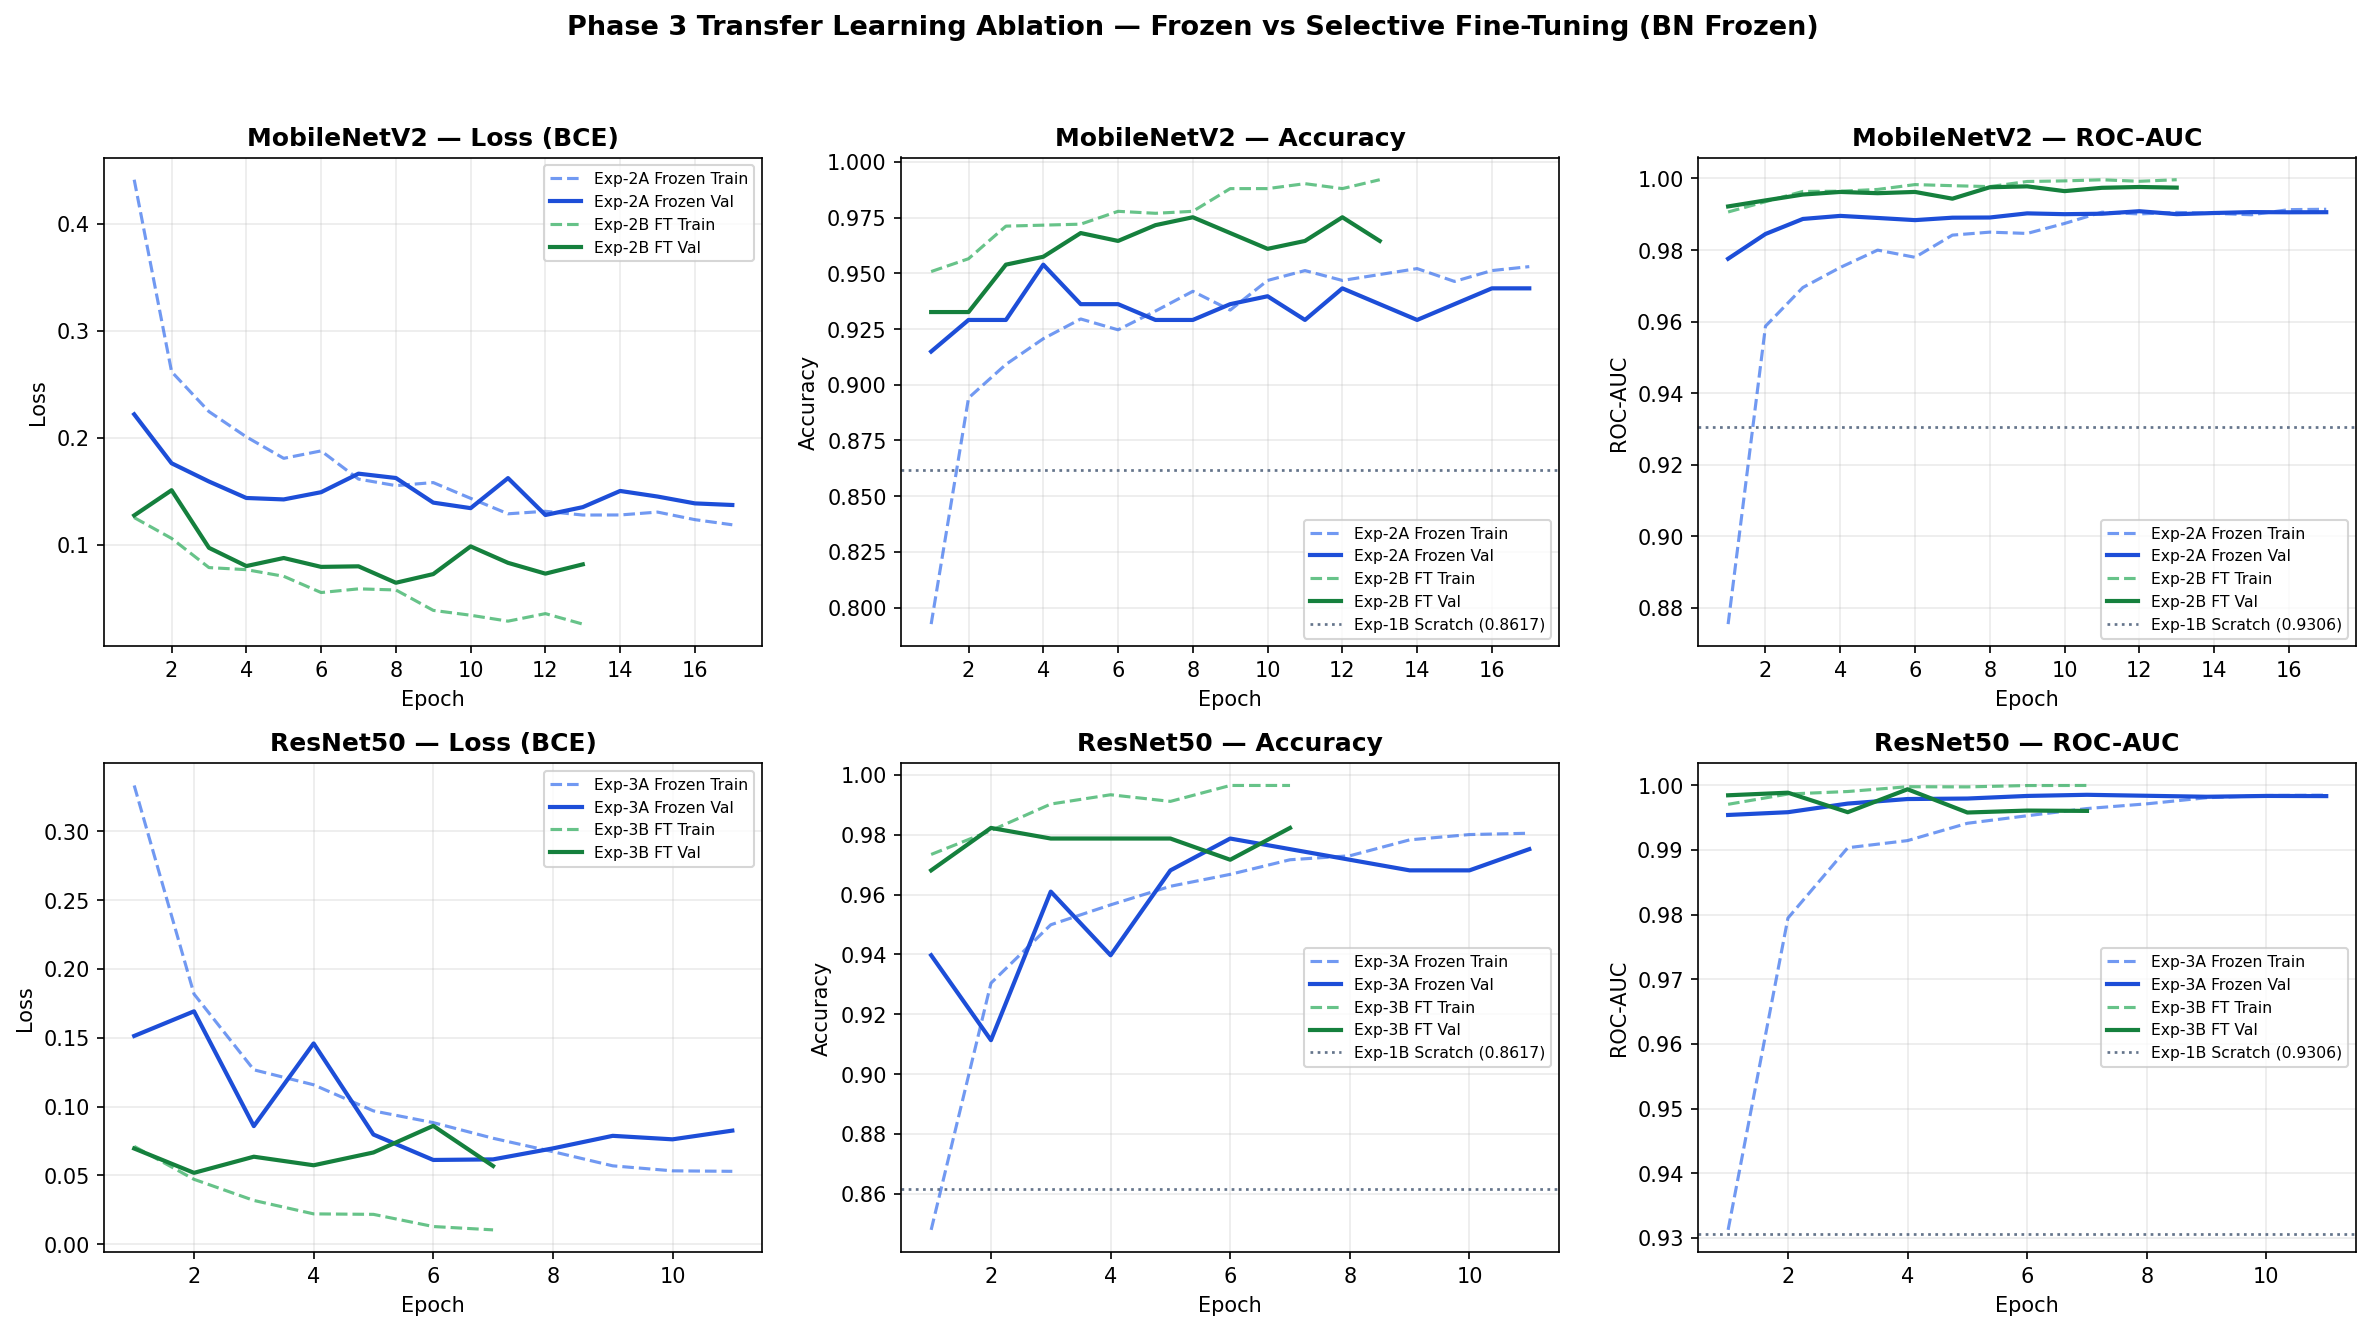

,params_total,params_trainable,model_size_mb,val_accuracy,val_loss,val_precision,val_recall,val_f1,val_roc_auc,mean_sec_per_epoch
Exp-1A,23907521,23907521,273.64,0.7943,0.4869,0.8387,0.7324,0.7820,0.8554,20.57
Exp-1B,422881,422881,4.92,0.8617,0.3547,0.8872,0.8310,0.8582,0.9306,57.00
Exp-2A,2422081,164097,11.06,0.9433,0.1277,0.9375,0.9507,0.9441,0.9909,30.41
Exp-2B,2422081,1943233,24.65,0.9752,0.0643,0.9720,0.9789,0.9754,0.9975,26.99
Exp-3A,23850113,262401,93.62,0.9787,0.0612,0.9722,0.9859,0.9790,0.9983,31.38
Exp-3B,23850113,17447169,224.75,0.9823,0.0519,0.9790,0.9859,0.9825,0.9989,37.79


{
  "Exp-2A": {
    "params_total": 2422081,
    "params_trainable": 164097,
    "model_size_mb": 11.06,
    "epochs_run": 17,
    "best_epoch": 12,
    "mean_sec_per_epoch": 30.41,
    "best_train_acc": 0.9468,
    "final_train_acc": 0.953,
    "overfit_gap_best_ep": 0.0035,
    "val_loss": 0.1277,
    "val_accuracy": 0.9433,
    "val_precision": 0.9375,
    "val_recall": 0.9507,
    "val_f1": 0.9441,
    "val_roc_auc": 0.9909
  },
  "Exp-2B": {
    "params_total": 2422081,
    "params_trainable": 1943233,
    "model_size_mb": 24.65,
    "epochs_run": 13,
    "best_epoch": 8,
    "mean_sec_per_epoch": 26.99,
    "best_train_acc": 0.9778,
    "final_train_acc": 0.992,
    "overfit_gap_best_ep": 0.0026,
    "val_loss": 0.0643,
    "val_accuracy": 0.9752,
    "val_precision": 0.972,
    "val_recall": 0.9789,
    "val_f1": 0.9754,
    "val_roc_auc": 0.9975,
    "total_backbone_layers": 154,
    "freeze_until_idx": 107,
    "bn_layers_kept_frozen": 52,
    "unfrozen_non_bn_layers": 31
  },

In [14]:
# Ablation Summary, 2x3 Learning Curves & Auto-Save to Google Drive
def _to_float_hist(hist_obj):
    return {k: [float(v) for v in vals] for k, vals in hist_obj.history.items()}

histories = {
    'Exp-2A': (_to_float_hist(exp2a_hist), exp2a_times, exp2a_ckpt, exp2a_val, (p_total_2a, p_train_2a), {}),
    'Exp-2B': (_to_float_hist(exp2b_hist), exp2b_times, exp2b_ckpt, exp2b_val, (p_total_2b, p_train_2b), mnet_ft_info),
    'Exp-3A': (_to_float_hist(exp3a_hist), exp3a_times, exp3a_ckpt, exp3a_val, (p_total_3a, p_train_3a), {}),
    'Exp-3B': (_to_float_hist(exp3b_hist), exp3b_times, exp3b_ckpt, exp3b_val, (p_total_3b, p_train_3b), resnet_ft_info),
}

for run_id, (h, times, _, _, _, _) in histories.items():
    fname = f"{run_id.lower().replace('-', '')}_history.json"
    with (EXPERIMENTS_DIR / fname).open('w', encoding='utf-8') as fh:
        json.dump({'history': h, 'epoch_times_sec': [round(t, 2) for t in times]}, fh, indent=2)

summary = {}
for run_id, (h, times, ckpt, val_m, (p_tot, p_tr), extra) in histories.items():
    best_ep = int(np.argmin(h['val_loss'])) + 1
    summary[run_id] = {
        'params_total': p_tot,
        'params_trainable': p_tr,
        'model_size_mb': round(ckpt.stat().st_size / (1024 * 1024), 2),
        'epochs_run': len(h['loss']),
        'best_epoch': best_ep,
        'mean_sec_per_epoch': round(float(np.mean(times)), 2),
        'best_train_acc': round(float(h['accuracy'][best_ep - 1]), 4),
        'final_train_acc': round(float(h['accuracy'][-1]), 4),
        'overfit_gap_best_ep': round(float(h['accuracy'][best_ep - 1] - val_m['val_accuracy']), 4),
        **val_m,
        **extra,
    }

with (EXPERIMENTS_DIR / 'phase3_summary.json').open('w', encoding='utf-8') as fh:
    json.dump(summary, fh, indent=2)

# Reference baseline from Phase 2
p2_path = EXPERIMENTS_DIR / 'phase2_summary.json'
p2_summary = json.loads(p2_path.read_text(encoding='utf-8')) if p2_path.exists() else {}
ref_acc = p2_summary.get('Exp-1B', {}).get('val_accuracy', 0.8617)
ref_auc = p2_summary.get('Exp-1B', {}).get('val_roc_auc', 0.9306)

# Plot 2x3 Learning Curves
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=150)
row_pairs = [
    ('MobileNetV2', 'Exp-2A', 'Exp-2B'),
    ('ResNet50', 'Exp-3A', 'Exp-3B'),
]
cols = [
    ('loss', 'Loss (BCE)', 'Loss', None),
    ('accuracy', 'Accuracy', 'Accuracy', ref_acc),
    ('roc_auc', 'ROC-AUC', 'ROC-AUC', ref_auc),
]

for r_idx, (title_prefix, id_a, id_b) in enumerate(row_pairs):
    ha = histories[id_a][0]
    hb = histories[id_b][0]
    ea = np.arange(1, len(ha['loss']) + 1)
    eb = np.arange(1, len(hb['loss']) + 1)
    for c_idx, (m_key, m_title, ylabel, ref_val) in enumerate(cols):
        ax = axes[r_idx, c_idx]
        ax.plot(ea, ha[m_key], '--', color='#2563eb', alpha=0.65, label=f'{id_a} Frozen Train')
        ax.plot(ea, ha[f'val_{m_key}'], '-', color='#1d4ed8', linewidth=2, label=f'{id_a} Frozen Val')
        ax.plot(eb, hb[m_key], '--', color='#16a34a', alpha=0.65, label=f'{id_b} FT Train')
        ax.plot(eb, hb[f'val_{m_key}'], '-', color='#15803d', linewidth=2, label=f'{id_b} FT Val')
        if ref_val is not None:
            ax.axhline(ref_val, color='#64748b', linestyle=':', linewidth=1.3, label=f'Exp-1B Scratch ({ref_val:.4f})')
        ax.set_title(f'{title_prefix} — {m_title}', fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7.5)

fig.suptitle('Phase 3 Transfer Learning Ablation — Frozen vs Selective Fine-Tuning (BN Frozen)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.95])
curves_path = FIGURES_DIR / 'phase3_transfer_learning_curves.png'
fig.savefig(curves_path, bbox_inches='tight')
plt.show()

# Combined Ablation Comparison Table (Phase 2 + Phase 3)
combined = {}
for k in ('Exp-1A', 'Exp-1B'):
    if k in p2_summary:
        combined[k] = {
            'params_total': p2_summary[k]['params'],
            'params_trainable': p2_summary[k]['params'],
            'model_size_mb': p2_summary[k]['model_size_mb'],
            'val_accuracy': p2_summary[k]['val_accuracy'],
            'val_loss': p2_summary[k]['val_loss'],
            'val_precision': p2_summary[k]['val_precision'],
            'val_recall': p2_summary[k]['val_recall'],
            'val_f1': p2_summary[k]['val_f1'],
            'val_roc_auc': p2_summary[k]['val_roc_auc'],
            'mean_sec_per_epoch': p2_summary[k]['mean_sec_per_epoch'],
        }
for k, v in summary.items():
    combined[k] = {
        'params_total': v['params_total'],
        'params_trainable': v['params_trainable'],
        'model_size_mb': v['model_size_mb'],
        'val_accuracy': v['val_accuracy'],
        'val_loss': v['val_loss'],
        'val_precision': v['val_precision'],
        'val_recall': v['val_recall'],
        'val_f1': v['val_f1'],
        'val_roc_auc': v['val_roc_auc'],
        'mean_sec_per_epoch': v['mean_sec_per_epoch'],
    }
display(pd.DataFrame.from_dict(combined, orient='index'))
print(json.dumps(summary, indent=2))

# Upsert into experiments/experiment_log.csv
log_df = pd.read_csv(EXPERIMENT_LOG_PATH)
now_str = datetime.now().astimezone().strftime('%Y-%m-%d %H:%M')
meta_map = {
    'Exp-2A': ('MobileNetV2', 'Frozen Feature Extractor', 'mobilenet_v2 [-1, 1] in-model'),
    'Exp-2B': ('MobileNetV2', 'Selective Fine-Tuning (top 30%, BN frozen)', 'mobilenet_v2 [-1, 1] in-model'),
    'Exp-3A': ('ResNet50', 'Frozen Feature Extractor', 'resnet50 (BGR mean sub) in-model'),
    'Exp-3B': ('ResNet50', 'Selective Fine-Tuning (top 30%, BN frozen)', 'resnet50 (BGR mean sub) in-model'),
}
new_rows = []
for run_id, v in summary.items():
    m_name, strat, pre = meta_map[run_id]
    new_rows.append({
        'run_id': run_id,
        'timestamp': now_str,
        'model': m_name,
        'strategy': strat,
        'preprocessing': pre,
        'params': f"{v['params_total']:,} ({v['params_trainable']:,} trainable)",
        'val_acc': v['val_accuracy'],
        'test_acc': 'LOCKED',
        'test_loss': 'LOCKED',
        'precision': 'LOCKED',
        'recall': 'LOCKED',
        'f1': 'LOCKED',
        'roc_auc': 'LOCKED',
        'time_per_epoch_sec': v['mean_sec_per_epoch'],
        'notes': (
            f"Best ep {v['best_epoch']}/{v['epochs_run']} | val_loss={v['val_loss']} | "
            f"val_f1={v['val_f1']} | val_auc={v['val_roc_auc']} | {v['model_size_mb']}MB"
        ),
    })
log_df = log_df[~log_df['run_id'].isin(list(meta_map.keys()))]
log_df = pd.concat([log_df, pd.DataFrame(new_rows)], ignore_index=True)
log_df.to_csv(EXPERIMENT_LOG_PATH, index=False)

# Auto-Save outputs to Google Drive when running in Colab
if IN_COLAB:
    drive_root = Path('/content/drive/MyDrive/Real-vs-AI-Art-Classification')
    if drive_root.exists():
        out_json_dir = drive_root / '01_Docs_&_Logs' / 'phase3_outputs'
        out_fig_dir = drive_root / '03_Figures_&_Visuals'
        out_mod_dir = drive_root / '04_Models'
        out_json_dir.mkdir(parents=True, exist_ok=True)
        out_fig_dir.mkdir(parents=True, exist_ok=True)
        out_mod_dir.mkdir(parents=True, exist_ok=True)

        for fpath in (
            EXPERIMENTS_DIR / 'phase3_summary.json',
            EXPERIMENTS_DIR / 'exp2a_history.json',
            EXPERIMENTS_DIR / 'exp2b_history.json',
            EXPERIMENTS_DIR / 'exp3a_history.json',
            EXPERIMENTS_DIR / 'exp3b_history.json',
            EXPERIMENT_LOG_PATH,
        ):
            shutil.copy2(fpath, out_json_dir / fpath.name)

        shutil.copy2(curves_path, out_fig_dir / curves_path.name)
        for ckpt in (exp2a_ckpt, exp2b_ckpt, exp3a_ckpt, exp3b_ckpt):
            shutil.copy2(ckpt, out_mod_dir / ckpt.name)

        print('Auto-saved Phase 3 JSONs, figures, and 4 .keras checkpoints to Google Drive!')
    else:
        print('Warning: Google Drive folder Real-vs-AI-Art-Classification not found at', drive_root)